In [ ]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import os

In [ ]:
import os

print(os.listdir("/content"))

['.config', 'sample_data']


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving dataset_simuteh.zip to dataset_simuteh.zip


In [ ]:
import os
import zipfile

os.makedirs("/content/data", exist_ok=True)

with zipfile.ZipFile("/content/dataset_simuteh.zip", "r") as zip_ref:
    zip_ref.extractall("/content/data")

print(os.listdir("/content/data"))

['data']


In [ ]:
import os

print(os.listdir("/content/data/data"))

['sintetis']


In [ ]:
import os

print(os.listdir("/content/data/data/sintetis"))

['bersih', 'label.csv', 'mask_bercak', 'citra', 'mask_daun']


In [ ]:
import os

print(os.listdir("/content/data/data/sintetis/bersih")[:10])

['teh_022.png', 'teh_047.png', 'teh_021.png', 'teh_009.png', 'teh_014.png', 'teh_034.png', 'teh_032.png', 'teh_001.png', 'teh_025.png', 'teh_050.png']


In [ ]:
nama = "teh_041.png"

bersih = cv2.imread(
    f"/content/data/data/sintetis/bersih/{nama}",
    cv2.IMREAD_GRAYSCALE
)

print("Ukuran citra:", bersih.shape)

Ukuran citra: (480, 640)


In [ ]:
kernels = {
    "rerata": np.ones((3, 3), dtype=float) / 9,
    "asimetris": np.array([
        [1, 0, -1],
        [2, 0, -2],
        [1, 0, -1]
    ], dtype=float)
}

for nm, k in kernels.items():
    t0 = time.perf_counter()
    a = konvolusi(bersih, k)
    t_manual = time.perf_counter() - t0

    t0 = time.perf_counter()
    b = cv2.filter2D(
        bersih, -1, k,
        borderType=cv2.BORDER_REPLICATE
    )
    t_cv = time.perf_counter() - t0

    c = konvolusi_sejati(bersih, k)

    beda = np.abs(a.astype(int) - b.astype(int)).max()
    beda2 = np.abs(c.astype(int) - b.astype(int)).max()

    print(
        f"{nm}: selisih manual vs filter2D={beda}, "
        f"sejati vs filter2D={beda2}, "
        f"waktu manual={t_manual:.3f} s, "
        f"filter2D={t_cv:.5f} s"
    )

rerata: selisih manual vs filter2D=0, sejati vs filter2D=0, waktu manual=2.097 s, filter2D=0.02589 s
asimetris: selisih manual vs filter2D=0, sejati vs filter2D=255, waktu manual=3.039 s, filter2D=0.00046 s


In [ ]:
def tambah_derau_gaussian(img, sigma, seed=1026):
    rng = np.random.default_rng(seed)
    noise = rng.normal(0, sigma, img.shape)
    hasil = img.astype(float) + noise
    return np.clip(hasil, 0, 255).astype(np.uint8)


def tambah_derau_sp(img, proporsi, seed=1026):
    rng = np.random.default_rng(seed)
    hasil = img.copy()

    jumlah = int(proporsi * img.size)
    indeks = rng.choice(img.size, jumlah, replace=False)

    setengah = jumlah // 2
    hasil.flat[indeks[:setengah]] = 0
    hasil.flat[indeks[setengah:]] = 255

    return hasil

In [ ]:
def buat_penapis(img):
    return {
        "Rerata 3x3": cv2.blur(img, (3, 3)),
        "Rerata 5x5": cv2.blur(img, (5, 5)),
        "Gaussian 5x5": cv2.GaussianBlur(img, (5, 5), 0),
        "Median 3x3": cv2.medianBlur(img, 3),
        "Median 5x5": cv2.medianBlur(img, 5),
        "Median 9x9": cv2.medianBlur(img, 9)
    }

In [ ]:
hasil_b4 = []

def uji_penapis(citra_asli, citra_derau, jenis_derau, tingkat):
    for nama, hasil in buat_penapis(citra_derau).items():

        waktu_awal = time.perf_counter()
        hasil = buat_penapis(citra_derau)[nama]
        waktu = time.perf_counter() - waktu_awal

        psnr = cv2.PSNR(citra_asli, hasil)

        hasil_b4.append({
            "Jenis Derau": jenis_derau,
            "Tingkat Derau": tingkat,
            "Penapis": nama,
            "PSNR (dB)": psnr,
            "Waktu (s)": waktu
        })

In [ ]:
# Derau Gaussian
for sigma in [10, 20, 40]:
    citra_derau = tambah_derau_gaussian(bersih, sigma)
    uji_penapis(bersih, citra_derau, "Gaussian", sigma)

# Derau salt-and-pepper
for tingkat in [0.04, 0.10]:
    citra_derau = tambah_derau_sp(bersih, tingkat)
    uji_penapis(bersih, citra_derau, "Salt-and-pepper", tingkat)

df_b4 = pd.DataFrame(hasil_b4)

display(df_b4)

,Jenis Derau,Tingkat Derau,Penapis,PSNR (dB),Waktu (s)
0,Gaussian,10.00,Rerata 3x3,36.859352,0.014711
1,Gaussian,10.00,Rerata 5x5,37.634532,0.017703
2,Gaussian,10.00,Gaussian 5x5,37.904888,0.015574
3,Gaussian,10.00,Median 3x3,35.518286,0.015212
4,Gaussian,10.00,Median 5x5,38.543209,0.015584
5,Gaussian,10.00,Median 9x9,38.976129,0.014969
6,Gaussian,20.00,Rerata 3x3,31.397618,0.015629
7,Gaussian,20.00,Rerata 5x5,34.427560,0.016044
8,Gaussian,20.00,Gaussian 5x5,32.907491,0.015661
9,Gaussian,20.00,Median 3x3,29.744966,0.015620


In [ ]:
df_b4.to_csv(
    "b4_tabel_penapis.csv",
    index=False
)

print("Tabel berhasil disimpan!")

Tabel berhasil disimpan!


In [ ]:
import pandas as pd

path_label = "/content/data/data/sintetis/label.csv"

label_df = pd.read_csv(path_label)

print("Kolom dataset:")
print(label_df.columns.tolist())

print("\nContoh data:")
display(label_df.head())

print("\nJumlah data berdasarkan label:")
display(label_df.iloc[:, -1].value_counts())

Kolom dataset:
['nama_file', 'kelas', 'kondisi_cahaya', 'persen_bercak']

Contoh data:


,nama_file,kelas,kondisi_cahaya,persen_bercak
0,teh_001.png,sehat,normal,0.0
1,teh_002.png,sehat,gelap,0.0
2,teh_003.png,sehat,terang,0.0
3,teh_004.png,sehat,kontras_rendah,0.0
4,teh_005.png,sehat,bayangan,0.0



Jumlah data berdasarkan label:


,count
persen_bercak,
0.00,20
0.66,2
0.56,2
0.65,1
0.60,1
0.38,1
0.42,1
0.43,1
0.73,1


In [ ]:
print("Jumlah data berdasarkan kelas:")
display(label_df["kelas"].value_counts())

print("\nDaftar kelas dan kondisi cahaya:")
display(
    label_df.groupby(["kelas", "kondisi_cahaya"])
    .size()
    .reset_index(name="jumlah")
)

Jumlah data berdasarkan kelas:


,count
kelas,
sehat,20
ringan,20
berat,20



Daftar kelas dan kondisi cahaya:


,kelas,kondisi_cahaya,jumlah
0,berat,bayangan,4
1,berat,gelap,4
2,berat,kontras_rendah,4
3,berat,normal,4
4,berat,terang,4
5,ringan,bayangan,4
6,ringan,gelap,4
7,ringan,kontras_rendah,4
8,ringan,normal,4
9,ringan,terang,4


In [ ]:
import os
import cv2
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ambil 20 citra dengan kelas ringan
data_ringan = label_df[label_df["kelas"] == "ringan"].copy()

hasil_b44 = []

ukuran_kernel = [3, 5, 7, 9]

for _, baris in data_ringan.iterrows():

    nama_file = baris["nama_file"]
    path = f"/content/data/data/sintetis/bersih/{nama_file}"

    citra = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if citra is None:
        print("Citra tidak ditemukan:", nama_file)
        continue

    for k in ukuran_kernel:

        mulai = time.perf_counter()

        hasil = cv2.GaussianBlur(
            citra, (k, k), 0
        )

        waktu = time.perf_counter() - mulai

        # Rata-rata selisih absolut intensitas
        dI = np.mean(
            np.abs(
                citra.astype(np.float32) -
                hasil.astype(np.float32)
            )
        )

        hasil_b44.append({
            "Nama File": nama_file,
            "Kondisi Cahaya": baris["kondisi_cahaya"],
            "Ukuran Kernel": f"{k}x{k}",
            "dI": round(dI, 4),
            "Waktu (detik)": round(waktu, 6)
        })

df_b44 = pd.DataFrame(hasil_b44)

print("Pengujian B4.4 selesai!")
print("Jumlah pengujian:", len(df_b44))
display(df_b44.head(10))

Pengujian B4.4 selesai!
Jumlah pengujian: 80


,Nama File,Kondisi Cahaya,Ukuran Kernel,dI,Waktu (detik)
0,teh_021.png,normal,3x3,0.3336,0.000246
1,teh_021.png,normal,5x5,0.5228,0.000429
2,teh_021.png,normal,7x7,0.7092,0.002142
3,teh_021.png,normal,9x9,0.8257,0.000699
4,teh_022.png,gelap,3x3,0.3280,0.000271
5,teh_022.png,gelap,5x5,0.5150,0.000396
6,teh_022.png,gelap,7x7,0.7043,0.000565
7,teh_022.png,gelap,9x9,0.8211,0.000708
8,teh_023.png,terang,3x3,0.3383,0.000249
9,teh_023.png,terang,5x5,0.5312,0.000328


,Ukuran Kernel,dI,Waktu (detik)
0,3x3,0.347570,0.000277
1,5x5,0.547895,0.000402
2,7x7,0.755270,0.000657
3,9x9,0.889580,0.000760


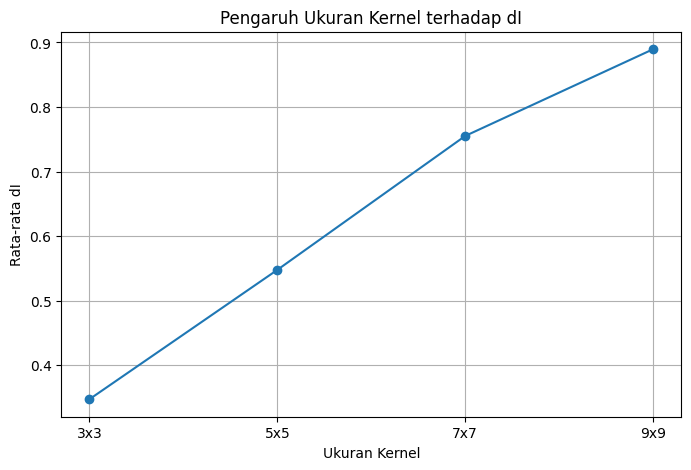

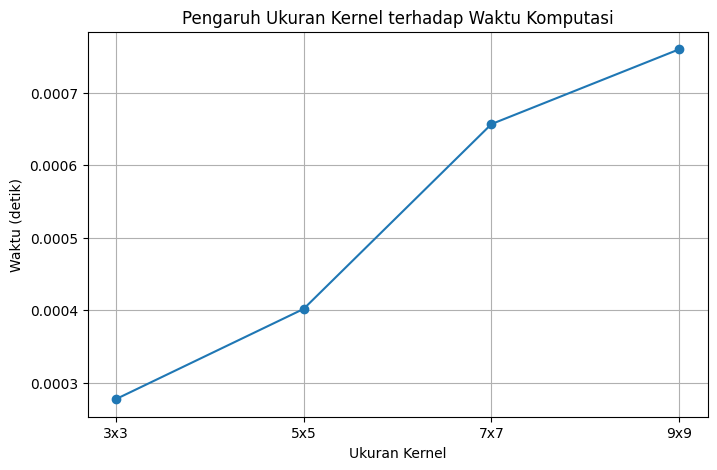

In [ ]:
ringkasan_b44 = (
    df_b44.groupby("Ukuran Kernel")
    [["dI", "Waktu (detik)"]]
    .mean()
    .reset_index()
)

display(ringkasan_b44)

plt.figure(figsize=(8, 5))
plt.plot(
    ringkasan_b44["Ukuran Kernel"],
    ringkasan_b44["dI"],
    marker="o"
)
plt.title("Pengaruh Ukuran Kernel terhadap dI")
plt.xlabel("Ukuran Kernel")
plt.ylabel("Rata-rata dI")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(
    ringkasan_b44["Ukuran Kernel"],
    ringkasan_b44["Waktu (detik)"],
    marker="o"
)
plt.title("Pengaruh Ukuran Kernel terhadap Waktu Komputasi")
plt.xlabel("Ukuran Kernel")
plt.ylabel("Waktu (detik)")
plt.grid(True)
plt.show()

In [ ]:
df_b44.to_csv("b4_4_pengaruh_kernel.csv", index=False)
ringkasan_b44.to_csv("b4_4_ringkasan_kernel.csv", index=False)

print("Kedua tabel berhasil disimpan!")

Kedua tabel berhasil disimpan!


In [ ]:
import os

folder_mask = "/content/data/data/sintetis/mask_daun"

print("Contoh file mask:")
print(os.listdir(folder_mask)[:10])

Contoh file mask:
['teh_022.png', 'teh_047.png', 'teh_021.png', 'teh_009.png', 'teh_014.png', 'teh_034.png', 'teh_032.png', 'teh_001.png', 'teh_025.png', 'teh_050.png']


In [ ]:
import cv2
import numpy as np
import pandas as pd
import time

hasil_b45 = []

# Ambil 20 citra bercak ringan
data_ringan = label_df[label_df["kelas"] == "ringan"]

for _, baris in data_ringan.iterrows():

    nama = baris["nama_file"]

    path_citra = f"/content/data/data/sintetis/bersih/{nama}"
    path_mask = f"/content/data/data/sintetis/mask_daun/{nama}"

    citra = cv2.imread(path_citra, cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(path_mask, cv2.IMREAD_GRAYSCALE)

    if citra is None or mask is None:
        print("File tidak ditemukan:", nama)
        continue

    # Tambahkan derau Gaussian
    derau = tambah_derau_gaussian(citra, 20)

    # Kernel penajaman
    kernel_tajam = np.array([
        [0, -1, 0],
        [-1, 5, -1],
        [0, -1, 0]
    ])

    # Urutan 1: penajaman lalu pengurangan derau
    tajam_dulu = cv2.filter2D(
        derau, -1, kernel_tajam
    )
    hasil_1 = cv2.GaussianBlur(
        tajam_dulu, (5, 5), 0
    )

    # Urutan 2: pengurangan derau lalu penajaman
    halus_dulu = cv2.GaussianBlur(
        derau, (5, 5), 0
    )
    hasil_2 = cv2.filter2D(
        halus_dulu, -1, kernel_tajam
    )

    # Hitung PSNR
    psnr_1 = cv2.PSNR(citra, hasil_1)
    psnr_2 = cv2.PSNR(citra, hasil_2)

    # Area latar belakang = bagian di luar daun
    latar = mask == 0

    std_1 = np.std(hasil_1[latar])
    std_2 = np.std(hasil_2[latar])

    hasil_b45.append({
        "Nama File": nama,
        "PSNR Tajam-Halus": round(psnr_1, 2),
        "PSNR Halus-Tajam": round(psnr_2, 2),
        "STD Latar Tajam-Halus": round(std_1, 2),
        "STD Latar Halus-Tajam": round(std_2, 2)
    })

df_b45 = pd.DataFrame(hasil_b45)

print("Pengujian B4.5 selesai!")
print("Jumlah citra:", len(df_b45))
display(df_b45)

Pengujian B4.5 selesai!
Jumlah citra: 20


,Nama File,PSNR Tajam-Halus,PSNR Halus-Tajam,STD Latar Tajam-Halus,STD Latar Halus-Tajam
0,teh_021.png,23.19,27.51,10.76,10.85
1,teh_022.png,24.10,27.52,10.64,10.86
2,teh_023.png,23.58,27.51,10.74,10.85
3,teh_024.png,21.64,27.53,11.03,10.87
4,teh_025.png,21.53,27.53,11.05,10.86
5,teh_026.png,22.85,27.51,10.94,10.97
6,teh_027.png,22.52,27.51,10.90,10.91
7,teh_028.png,21.24,27.54,11.12,10.92
8,teh_029.png,21.77,27.52,11.04,10.89
9,teh_030.png,23.30,27.51,10.73,10.88


In [ ]:
ringkasan_b45 = df_b45.select_dtypes(
    include="number"
).mean().to_frame("Rata-rata")

display(ringkasan_b45)

,Rata-rata
PSNR Tajam-Halus,22.4760
PSNR Halus-Tajam,27.5180
STD Latar Tajam-Halus,10.9305
STD Latar Halus-Tajam,10.9080


In [ ]:
df_b45.to_csv("b4_5_urutan_penapisan.csv", index=False)

print("File B4.5 berhasil disimpan!")

File B4.5 berhasil disimpan!


In [ ]:
data_normal = label_df[
    label_df["kondisi_cahaya"].str.lower() == "normal"
].head(12)

print("Jumlah citra:", len(data_normal))
display(data_normal[["nama_file", "kelas", "kondisi_cahaya"]])

Jumlah citra: 12


,nama_file,kelas,kondisi_cahaya
0,teh_001.png,sehat,normal
5,teh_006.png,sehat,normal
10,teh_011.png,sehat,normal
15,teh_016.png,sehat,normal
20,teh_021.png,ringan,normal
25,teh_026.png,ringan,normal
30,teh_031.png,ringan,normal
35,teh_036.png,ringan,normal
40,teh_041.png,berat,normal
45,teh_046.png,berat,normal


In [ ]:
hasil_b46 = []

for _, baris in data_normal.iterrows():
    nama = baris["nama_file"]
    path = f"/content/data/data/sintetis/bersih/{nama}"

    citra = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if citra is None:
        print("Gagal membaca:", nama)
        continue

    # Menambahkan derau Gaussian
    derau = tambah_derau_gaussian(citra, 20)

    # PSNR sebelum filtering
    psnr_sebelum = cv2.PSNR(citra, derau)

    # Filtering Gaussian 5x5
    hasil = cv2.GaussianBlur(derau, (5, 5), 0)

    # PSNR sesudah filtering
    psnr_sesudah = cv2.PSNR(citra, hasil)

    hasil_b46.append({
        "Nama File": nama,
        "Kelas": baris["kelas"],
        "PSNR Sebelum": psnr_sebelum,
        "PSNR Sesudah": psnr_sesudah,
        "Peningkatan PSNR": psnr_sesudah - psnr_sebelum
    })

df_b46 = pd.DataFrame(hasil_b46)

display(df_b46.round(4))

,Nama File,Kelas,PSNR Sebelum,PSNR Sesudah,Peningkatan PSNR
0,teh_001.png,sehat,22.1051,33.0220,10.9168
1,teh_006.png,sehat,22.1248,33.0077,10.8829
2,teh_011.png,sehat,22.1036,33.0136,10.9101
3,teh_016.png,sehat,22.1091,33.0183,10.9091
4,teh_021.png,ringan,22.1044,33.0520,10.9476
5,teh_026.png,ringan,22.1070,32.9845,10.8775
6,teh_031.png,ringan,22.1116,32.9615,10.8499
7,teh_036.png,ringan,22.1129,32.9561,10.8432
8,teh_041.png,berat,22.1120,32.9075,10.7955
9,teh_046.png,berat,22.1140,32.8990,10.7850


In [ ]:
print("Rata-rata PSNR Sebelum:",
      df_b46["PSNR Sebelum"].mean())

print("Rata-rata PSNR Sesudah:",
      df_b46["PSNR Sesudah"].mean())

print("Rata-rata Peningkatan:",
      df_b46["Peningkatan PSNR"].mean())

Rata-rata PSNR Sebelum: 22.109470840739984
Rata-rata PSNR Sesudah: 32.975495731161864
Rata-rata Peningkatan: 10.866024890421885


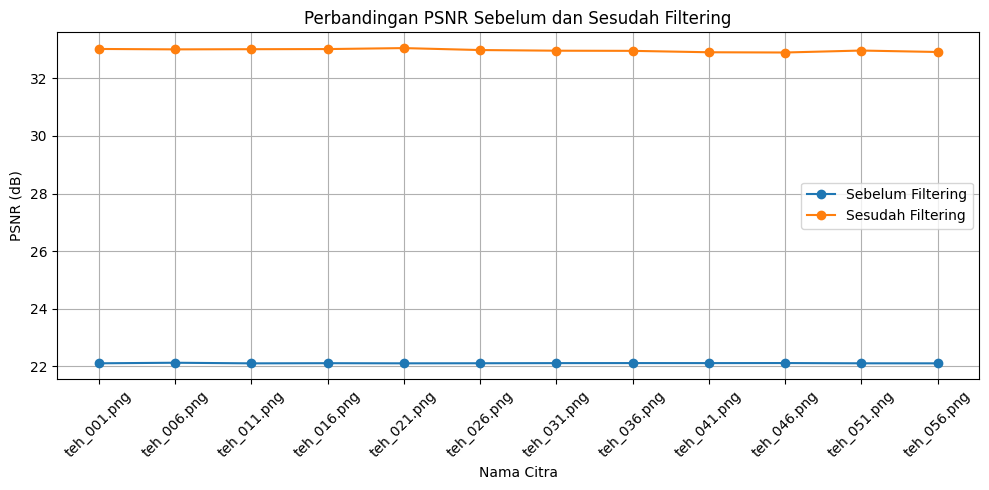

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(df_b46["Nama File"], df_b46["PSNR Sebelum"],
         marker="o", label="Sebelum Filtering")

plt.plot(df_b46["Nama File"], df_b46["PSNR Sesudah"],
         marker="o", label="Sesudah Filtering")

plt.xlabel("Nama Citra")
plt.ylabel("PSNR (dB)")
plt.title("Perbandingan PSNR Sebelum dan Sesudah Filtering")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
df_b46.to_csv("b4_6_perbandingan_psnr.csv", index=False)

from google.colab import files
files.download("b4_6_perbandingan_psnr.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
hasil_b46 = []

data_normal = label_df[
    label_df["kondisi_cahaya"].str.lower() == "normal"
].sort_values("nama_file")

for _, baris in data_normal.iterrows():
    nama = baris["nama_file"]

    path_citra = f"/content/data/data/sintetis/citra/{nama}"
    path_bersih = f"/content/data/data/sintetis/bersih/{nama}"

    citra_berderau = cv2.imread(path_citra, cv2.IMREAD_GRAYSCALE)
    citra_bersih = cv2.imread(path_bersih, cv2.IMREAD_GRAYSCALE)

    if citra_berderau is None or citra_bersih is None:
        print("Gagal membaca:", nama)
        continue

    # PSNR sebelum filtering
    psnr_sebelum = cv2.PSNR(citra_bersih, citra_berderau)

    # Filter pilihan: Gaussian 5x5
    hasil = cv2.GaussianBlur(citra_berderau, (5, 5), 0)

    # PSNR sesudah filtering
    psnr_sesudah = cv2.PSNR(citra_bersih, hasil)

    hasil_b46.append({
        "Nama File": nama,
        "PSNR Sebelum": psnr_sebelum,
        "PSNR Sesudah": psnr_sesudah,
        "Peningkatan PSNR": psnr_sesudah - psnr_sebelum
    })

df_b46 = pd.DataFrame(hasil_b46)

display(df_b46.round(4))

print("Jumlah citra:", len(df_b46))
print("Rata-rata PSNR sebelum:",
      df_b46["PSNR Sebelum"].mean())
print("Rata-rata PSNR sesudah:",
      df_b46["PSNR Sesudah"].mean())
print("Rata-rata peningkatan:",
      df_b46["Peningkatan PSNR"].mean())

df_b46.to_csv("b4_6_perbandingan_psnr.csv", index=False)

,Nama File,PSNR Sebelum,PSNR Sesudah,Peningkatan PSNR
0,teh_001.png,31.9089,40.9983,9.0894
1,teh_006.png,29.4145,39.2016,9.7871
2,teh_011.png,29.8428,39.6066,9.7639
3,teh_016.png,31.6506,40.8370,9.1864
4,teh_021.png,29.8485,39.7532,9.9047
5,teh_026.png,35.8990,42.5109,6.6118
6,teh_031.png,29.0942,38.8102,9.7160
7,teh_036.png,29.9789,39.4174,9.4385
8,teh_041.png,30.6648,39.5619,8.8971
9,teh_046.png,31.9119,40.1922,8.2803


Jumlah citra: 12
Rata-rata PSNR sebelum: 31.06056999292709
Rata-rata PSNR sesudah: 40.085614008204594
Rata-rata peningkatan: 9.025044015277507
